In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2, cauchy, norm


In [ ]:
chi2.rvs(df=1, size=100000)

array([0.07275973, 5.4568451 , 0.65992197, ..., 4.05224655, 3.95650269,
       2.18897514])

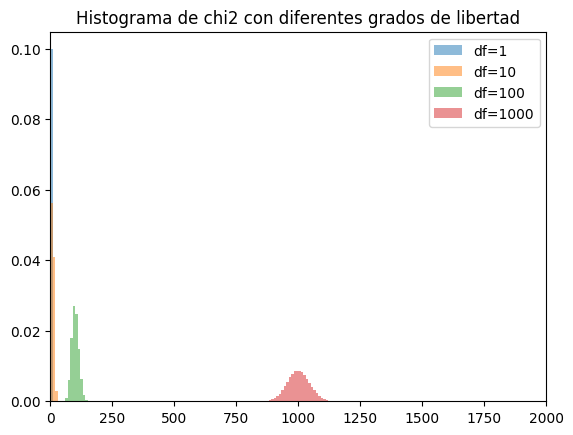

In [ ]:
n = [1,10,100,1000]
bins = np.arange(0, 2010, 10)
chi = []
for i in n:
  datos = chi2.rvs(df=i, size=100000)
  plt.hist(datos, bins=bins, density=True, alpha=0.5, label=f"df={i}")
plt.legend()
plt.title("Histograma de chi2 con diferentes grados de libertad")
plt.xlim(0,2000)
plt.show()

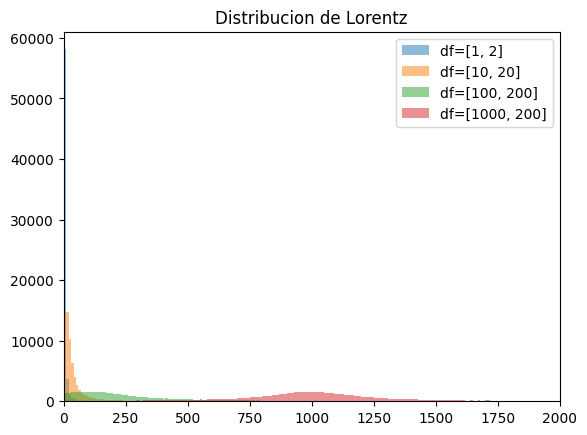

In [ ]:
cosas = [[1,2],[10,20],[100,200],[1000,200]]
for i in cosas:
  distribucion = cauchy.rvs(loc=i[0], scale=i[1], size=100000)
  p1, p99 = np.percentile(distribucion, [1, 99])
  plt.hist(distribucion, bins=bins, alpha=0.5, label=f"df={i}")
plt.legend()
plt.xlim(0,2000)
plt.title("Distribucion de Lorentz")
plt.show()

Text(0.5, 1.0, 'Distribucion de normal')

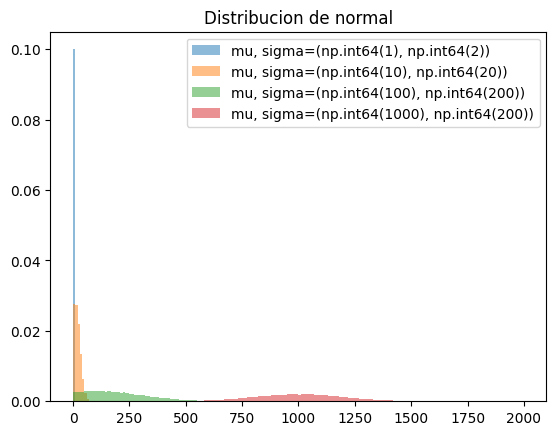

In [ ]:
mu = np.array([1, 10, 100, 1000])
sigma = np.array([2, 20, 200, 200])

bins = np.arange(0, 2010, 10)

for i in range(len(mu)):
  plt.hist(norm.rvs(loc=mu[i], scale=sigma[i], size=100000), bins=bins, alpha=0.5, label=f"mu, sigma={mu[i], sigma[i]}", density= True)

plt.legend()
plt.title("Distribucion de normal")

array([-3.82686302e+00,  9.52803410e+00,  7.34190994e-01, ...,
       -9.84983977e+00, -9.26914466e-03,  5.27669921e-01])

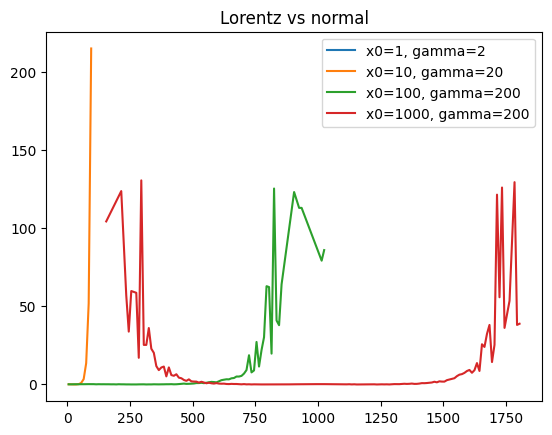

In [ ]:
cosas = [[1,2],[10,20],[100,200],[1000,200]]

for i in cosas:
  datos = cauchy.rvs(loc=i[0], scale=i[1], size=100000)
  datos_nor = norm.rvs(loc=i[0], scale=i[1], size=100000)
  L,_ = np.histogram(datos,bins=bins, density=True)
  N,_ = np.histogram(datos_nor,bins=bins, density=True)
  indice = N > 0
  total = (L[indice]-N[indice])/N[indice]
  eje_x = (bins[:-1]+bins[1:])/2
  plt.plot(eje_x[indice], total, label=f"x0={i[0]}, gamma={i[1]}")
plt.title("Lorentz vs normal")
plt.legend()
plt.show()


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

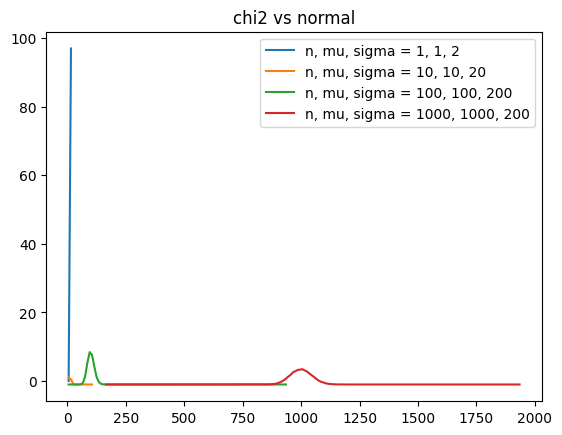

In [ ]:
mu = np.array([1, 10, 100, 1000])
sigma = np.array([2, 20, 200, 200])
n = [1,10,100,1000]

for i in range(len(mu)):
  datos = chi2.rvs(df=n[i], size=100000)
  datos_nor = norm.rvs(loc=mu[i], scale=sigma[i], size=100000)
  L,_ = np.histogram(datos,bins=bins, density=True)
  N,_ = np.histogram(datos_nor,bins=bins, density=True)
  indice = N > 0
  total = (L[indice]-N[indice])/N[indice]
  eje_x = (bins[:-1]+bins[1:])/2
  plt.plot(eje_x[indice], total, label=f"n, mu, sigma = {n[i]}, {mu[i]}, {sigma[i]}")
plt.title("chi2 vs normal")
plt.legend()
plt.savefig("grafica6.pdf")
files.download("grafica6.pdf")
plt.show()